Epoch 1: Weights=[0.1 0.1], Bias=0.0, Error=2
Epoch 2: Weights=[0.2 0.1], Bias=-0.1, Error=3
Epoch 3: Weights=[0.2 0.1], Bias=-0.20000000000000004, Error=3
Epoch 4: Weights=[0.2 0.1], Bias=-0.20000000000000004, Error=0
Epoch 5: Weights=[0.2 0.1], Bias=-0.20000000000000004, Error=0
Epoch 6: Weights=[0.2 0.1], Bias=-0.20000000000000004, Error=0
Epoch 7: Weights=[0.2 0.1], Bias=-0.20000000000000004, Error=0
Epoch 8: Weights=[0.2 0.1], Bias=-0.20000000000000004, Error=0
Epoch 9: Weights=[0.2 0.1], Bias=-0.20000000000000004, Error=0
Epoch 10: Weights=[0.2 0.1], Bias=-0.20000000000000004, Error=0

AND GATE PREDICTIONS
Input: [0 0] Target: 0 Prediction: 0
Input: [0 1] Target: 0 Prediction: 0
Input: [1 0] Target: 0 Prediction: 0
Input: [1 1] Target: 1 Prediction: 1

FORWARD PROPAGATION
Input: [[0.8 0.4]]
Hidden Weighted Sum: [[0.46 0.54 0.62]]
Hidden Activation: [[0.46 0.54 0.62]]
Output Weighted Sum: [[0.94]]
Final Output: [[0.71909966]]


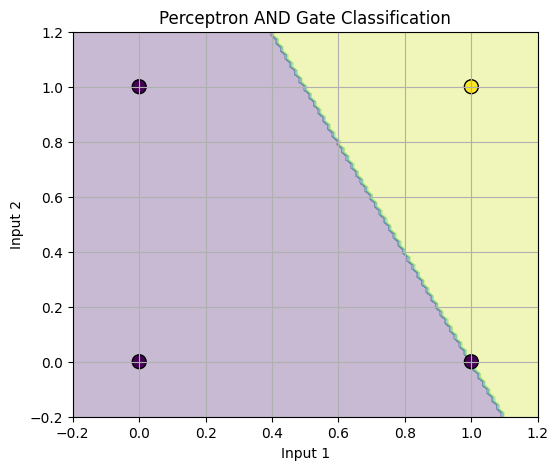

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define activation functions
def step_function(x):
    return np.where(x >= 0, 1, 0)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def relu(x):
    return np.maximum(0, x)

# 2. AND gate dataset
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 0, 0, 1])

# 3. Initialize weights and bias
weights = np.zeros(2)
bias = 0.0

learning_rate = 0.1
epochs = 10

# 4. Train perceptron
for epoch in range(epochs):

    total_error = 0

    for inputs, target in zip(X, y):

        weighted_sum = np.dot(
            inputs, weights
        ) + bias

        prediction = step_function(
            weighted_sum
        )

        error = target - prediction

        weights += (
            learning_rate * error * inputs
        )

        bias += learning_rate * error

        total_error += abs(error)

    print(
        f"Epoch {epoch+1}: "
        f"Weights={weights}, "
        f"Bias={bias}, "
        f"Error={total_error}"
    )

# 5. Test perceptron
print("\nAND GATE PREDICTIONS")

for inputs, target in zip(X, y):

    z = np.dot(inputs, weights) + bias

    prediction = step_function(z)

    print(
        "Input:", inputs,
        "Target:", target,
        "Prediction:", prediction
    )

# 6. Forward propagation
input_data = np.array([[0.8, 0.4]])

W1 = np.array([
    [0.2, 0.4, 0.6],
    [0.5, 0.3, 0.1]
])

b1 = np.array([[0.1, 0.1, 0.1]])

W2 = np.array([
    [0.7],
    [0.2],
    [0.5]
])

b2 = np.array([[0.2]])

# Hidden layer
z1 = np.dot(input_data, W1) + b1

a1 = relu(z1)

# Output layer
z2 = np.dot(a1, W2) + b2

a2 = sigmoid(z2)

print("\nFORWARD PROPAGATION")

print("Input:", input_data)

print("Hidden Weighted Sum:", z1)

print("Hidden Activation:", a1)

print("Output Weighted Sum:", z2)

print("Final Output:", a2)

# 7. Visualize perceptron
xx, yy = np.meshgrid(
    np.linspace(-0.2, 1.2, 100),
    np.linspace(-0.2, 1.2, 100)
)

grid = np.c_[xx.ravel(), yy.ravel()]

zz = step_function(
    grid @ weights + bias
).reshape(xx.shape)

plt.figure(figsize=(6, 5))

plt.contourf(
    xx, yy, zz,
    alpha=0.3
)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    edgecolors="black",
    s=100
)

plt.xlabel("Input 1")
plt.ylabel("Input 2")

plt.title(
    "Perceptron AND Gate Classification"
)

plt.grid()
plt.show()